In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import seaborn as sns
import os
from scipy.stats import chi2_contingency, MonteCarloMethod

import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))
from src.utils import (
    load_data,
    class_distribution,
)

## ***1. Wczytanie metadanych i sprawdzenie integralności.***

In [2]:
DATASET_PATH = Path("../dataset/HAM10000_metadata")

df=load_data(DATASET_PATH)

Dataset loaded.


In [3]:
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,vidir_modern
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,vidir_modern
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,vidir_modern
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,vidir_modern
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,vidir_modern


### 1.2. Kontrola integralności zbioru.

Czy istnieją identyfikatory zdjęcia (`image_id`), którym odpowiadający obraz nie istnieje w zbiorze?

In [4]:
image_dir = Path('../dataset/HAM10000_images')
filenames = [x.name for x in image_dir.iterdir() if x.is_file()]
print(f"Number of images: {len(filenames)}")

Number of images: 10015


In [5]:
orphan_ids=0

for img_id in df['image_id']:
    if img_id+".jpg" not in filenames:
        orphan_ids+=1

print(f"Number of orphan ids: {orphan_ids}")

Number of orphan ids: 0


W zbiorze nie występują wartości osierocone - każda wartość z kolumny `image_id` ma przypisany do siebie obraz zmiany skórnej.

## ***2. Analiza danych***  
W analizie zostaną pominięte kolumny `dx_type` oraz `dataset`, jako że nie posiadają one żadnej wartości predykcyjnej - dotyczą one jedynie pochodzenia danych oraz sposobu w jaki diagnoza została potwierdzona.

### 2.1. Analiza braków danych (NaN), unknown i wartości zerowych

In [6]:
print(f"Liczba brakujących pól w każdej kolumnie \n{df.isnull().sum()}")

Liczba brakujących pól w każdej kolumnie 
lesion_id        0
image_id         0
dx               0
dx_type          0
age             57
sex              0
localization     0
dataset          0
dtype: int64


Mamy do czynienia z 57 pustymi polami danych (NaN), jedynie w kolumnie z wiekiem pacjenta (`age`).

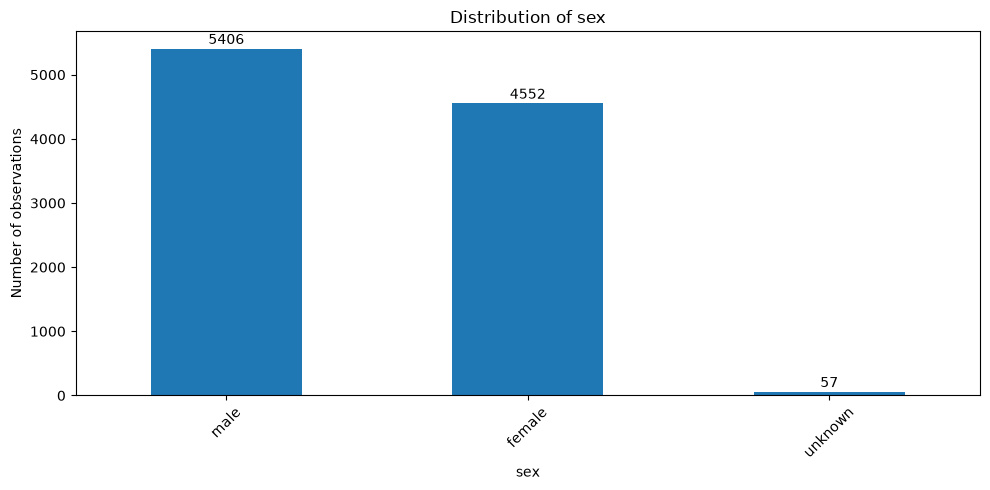

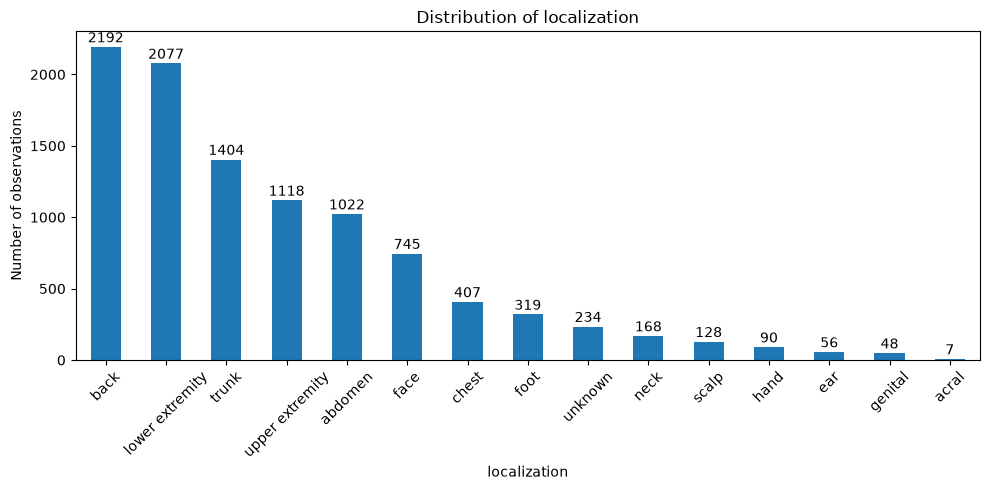

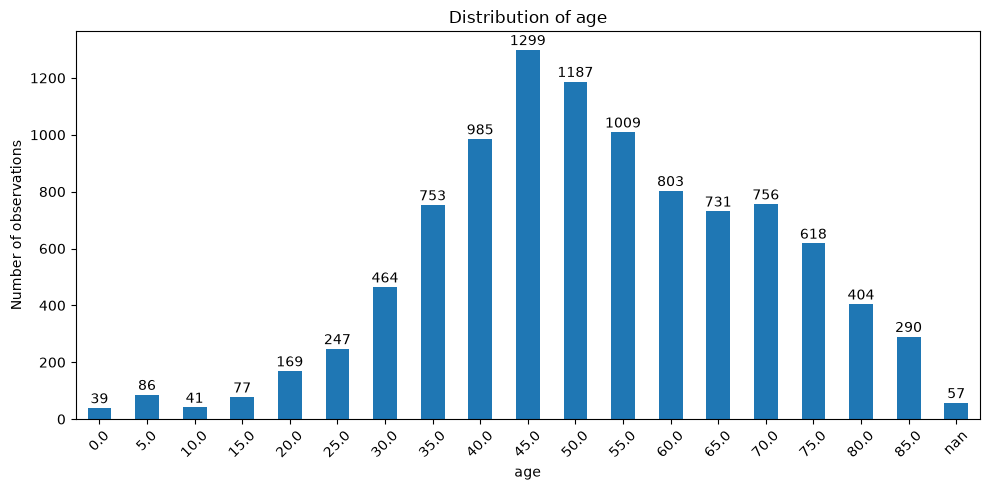

In [7]:
columns = ['sex', 'localization', 'age']

for col in columns:
    counts = df[col].value_counts(dropna=False)

    if col=='age': counts=counts.sort_index()
    
    plt.figure(figsize=(10, 5))
    bars = counts.plot(kind='bar')
    plt.bar_label(bars.containers[0], fmt='%d', padding=1)

    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Number of observations')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [8]:
for col in columns:
    unknown = (df[col] == 'unknown').sum()
    percent = unknown/len(df[col]) *100
    print(f"Wartości \"unknown\" w `{col}`: {unknown} . Procentowo: {percent:.2f}%.")

Wartości "unknown" w `sex`: 57 . Procentowo: 0.57%.
Wartości "unknown" w `localization`: 234 . Procentowo: 2.34%.
Wartości "unknown" w `age`: 0 . Procentowo: 0.00%.


W danych pojawiają się jednak wartości "unknown" lub "0" dla kolumny age. Należy rozważyć, czy potraktować je na równi z NaN. 

### Analiza przypadku "0" w kolumnie AGE

In [9]:
print(f"Liczba przypadków z `age` = 0:\t {df[df['age'] == 0].shape[0]}\n")

print(f"Procent przypadków `age` = 0:\t {(df['age'] == 0).mean() * 100:.2f}%\n")

print(f"Rozkład diagnoz dla `age` = 0: \n{df[df['age'] == 0]['dx'].value_counts()}")

Liczba przypadków z `age` = 0:	 39

Procent przypadków `age` = 0:	 0.39%

Rozkład diagnoz dla `age` = 0: 
dx
nv      30
bkl      5
vasc     4
Name: count, dtype: int64


Autorzy zbioru HAM10000 nie dostarczają informacji, czy wartość `age`=0 była użyta jako wartość zastępcza braku danych czy faktycznie oznacza, że pacjent był noworodkiem. Nie ma jednak wystarczających przesłanek, by potraktować tę wartość na równi z NaN.

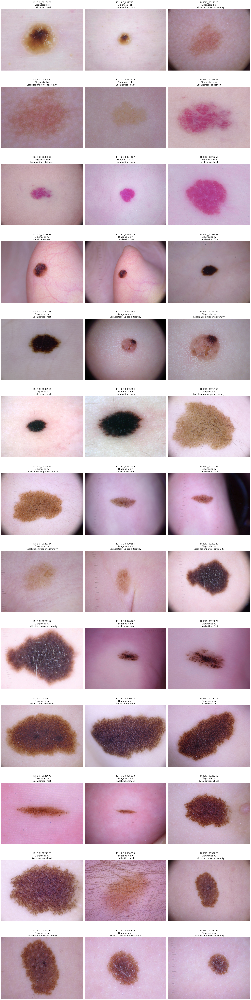

In [10]:
fig, axes = plt.subplots(13, 3, figsize=(20, 80))

for ax, (_, row) in zip(axes.flat, df[df['age'] == 0].iterrows()):

    image_path = os.path.join(
        image_dir,
        row['image_id'] + '.jpg'
    )

    img = Image.open(image_path)

    ax.imshow(img)
    ax.set_title(
        f"ID: {row['image_id']}\n"
        f"Diagnosis: {row['dx']}\n"
        f"Localization: {row['localization']}"
    )
    ax.axis('off')

plt.tight_layout()
plt.show()

Wizualna ocena rozważanych próbek nie daje podstaw by sądzić, że pacjentami nie mogły być noworodki. Wartość 0 w kolumnie `age` pozostanie niezmodyfikowana w zbiorze.

### 2.2. Analiza rozkładu wieku w podziale na diagnozę

In [11]:
age_info = df.groupby('dx')['age'].agg(
        ['mean', 'median', 'min', 'max', 'count']
    )
NaN_number = df['age'].isnull().groupby(df['dx']).sum().rename('NaN count')
age_info.join(NaN_number)

,mean,median,min,max,count,NaN count
dx,,,,,,
akiec,66.529052,70.0,30.0,85.0,327,0
bcc,66.828794,70.0,20.0,85.0,514,0
bkl,64.283747,65.0,0.0,85.0,1089,10
df,53.043478,50.0,25.0,80.0,115,0
mel,60.679568,60.0,5.0,85.0,1111,2
nv,46.477477,45.0,0.0,85.0,6660,45
vasc,51.373239,55.0,0.0,85.0,142,0


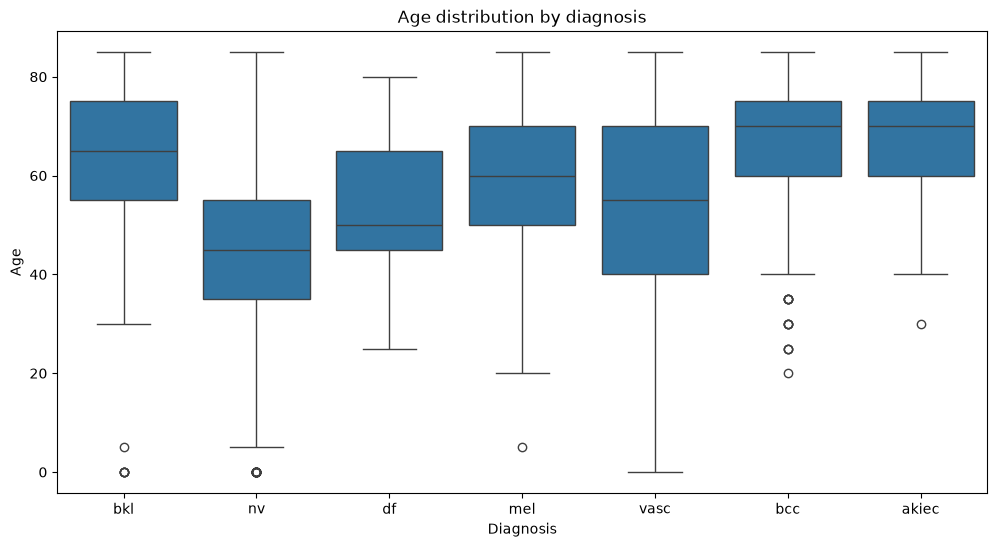

In [12]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="dx",
    y="age"
)

plt.title("Age distribution by diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Age")
plt.show()

### Interpretacja rozkładu wieku pacjentów w poszczególnych klasach diagnostycznych

Boxplot przedstawia rozkład wieku pacjentów (`age`) w zależności od klasy diagnostycznej (`dx`). Można zauważyć różnice w medianach wieku pomiędzy poszczególnymi klasami.

Najwyższe mediany wieku występują w klasach `bcc` oraz `akiec` i wynoszą około 70 lat. Stosunkowo wysoką medianę obserwujemy również dla `bkl` (około 65 lat) i `mel` (około 60 lat). Najniższa mediana występuje w klasie `nv` i wynosi około 45 lat.

Widoczne są również różnice w rozproszeniu danych. Szczególnie szeroki rozkład wieku występuje w klasie `vasc`, natomiast w klasach `bcc` i `akiec` większość obserwacji skupia się w wyższych przedziałach wiekowych. Na wykresie występują także wartości odstające, przede wszystkim w dolnych zakresach wieku.

Zaobserwowane różnice sugerują, że wiek pacjenta może być potencjalnie istotną cechą wspomagającą klasyfikację zmian skórnych (wzmożone ryzyko wystąpienia zmiany złośliwej). Nie jest to jednak zależnością przyczynową i nie pozwala on jednak samodzielnie rozróżnić wszystkich klas, ponieważ rozkłady wieku częściowo się pokrywają.


### 2.3. Rozkład płci w podziale na diagnozę

In [13]:
diagnosis_sex_prop = pd.crosstab(df['dx'], df['sex'], normalize='index') * 100
diagnosis_sex_prop

sex,female,male,unknown
dx,,,
akiec,32.415902,67.584098,0.000000
bcc,38.326848,61.673152,0.000000
bkl,42.129208,56.960874,0.909918
df,45.217391,54.782609,0.000000
mel,38.095238,61.904762,0.000000
nv,48.277405,51.021626,0.700969
vasc,51.408451,48.591549,0.000000


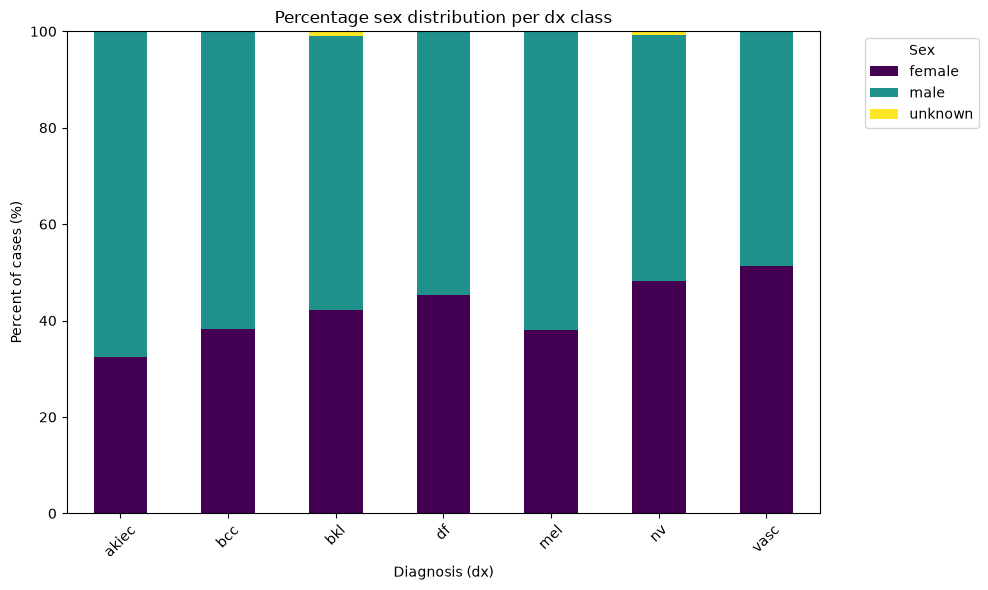

In [14]:
ax = diagnosis_sex_prop.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='viridis')

plt.title('Percentage sex distribution per dx class')
plt.xlabel('Diagnosis (dx)')
plt.ylabel('Percent of cases (%)')
plt.legend(title='Sex', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretacja rozkładu płci pacjentów w poszczególnych klasach diagnostycznych

Powyższy diagram przedstawia procentowy rozkład płci pacjentów (`sex`) w zależności od klasy diagnostycznej (`dx`).  

W prawie każdej z klas dominują mężczyźni. Wyjątkiem jest klasa `vasc`, gdzie nieznacznie większy udział mają kobiety. Największy udział mężczyzn występuje w klasie `akiec` i wynosi ~$67.6\%$, natomiast najmniejszy w klasie `vasc` na poziomie ~$48.6\%$

Różnica w procentowym udziale kobiet między klasami wynosi około $51.4-32.4=19.0$ punktów procentowych. Wskazuje to na pewne zróżnicowanie rozkładu płci pomiędzy diagnozami, jednak sama płeć nie wydaje się cechą silnie różnicującą wszystkie klasy.

Nie można jednak na podstawie samego wykresu wykluczyć jej wartości predykcyjnej. Płeć może stanowić dodatkową cechę wspomagającą klasyfikację zmian skórnych, dlatego jej rzeczywistą przydatność warto zweryfikować za pomocą testu statystycznego oraz porównania wyników modeli uwzględniających i pomijających tę zmienną.

#### Test chi-kwadrat niezależności

$H_0$: Badane zmienne są niezależne.

$H_1$: Badane zmienne są zależne.

In [15]:
df_sex = df[df["sex"].isin(["male", "female"])] #Pomijamy "unknown", jako że wartość ta zostanie imputowana

contingency_table = pd.crosstab(df_sex["sex"], df_sex["dx"])

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f"Chi-square: {chi2:.4f}")
print(f"p-value: {p_value:.5e}")

Chi-square: 89.6216
p-value: 3.63095e-17


Przed interpretacją wyniku należy sprawdzić, czy kryteria testu chi-kwadrat są spełnione:
 - żadna komórka nie powinna mieć expected < 1
 - maksymalnie 20% komórek może mieć expected < 5

In [16]:
# Tabela liczebności oczekiwanych
expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("Liczebności oczekiwane:")
display(expected_table.round(2))

# Kontrola założeń
print("Minimalna wartość expected:", expected.min())
print("Liczba komórek z expected < 5:", (expected < 5).sum())
print(
    "Procent komórek z expected < 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

Liczebności oczekiwane:


dx,akiec,bcc,bkl,df,mel,nv,vasc
sex,,,,,,,
female,149.48,234.96,497.8,52.57,508.77,3043.5,64.91
male,177.52,279.04,591.2,62.43,604.23,3614.5,77.09


Minimalna wartość expected: 52.568788913436435
Liczba komórek z expected < 5: 0
Procent komórek z expected < 5: 0.0 %


Kryteria są spełnione, więc możnma przejść do interpretacji wyniku.
Wartość $p < 0.05$ więc odrzucamy hipotezę zerową. Test udowodnił że między płcią pacjenta a diagnozą istnieje zależność. Siła tej zależności zostanie zmierzona testem V Cramera.

In [17]:
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.0949


Wartość współczynnika Cramera z przedziału $0.0-0.10$ sugeruje, że jest to bardzo słaba zależność. Na tej podstawie można zakładać, że płeć pacjenta nie będzie użyteczną cechą predykcyjną. Mimo to, w dalszej części pracy zostanie zbadany wpływ tej cechy na efektywność modelu, jako że może dostarczyć dodatkowe informacje.

### 2.4. Rozkład lokalizacji w podziale na diagnozę

In [18]:
diagnosis_loc_prop = pd.crosstab(df['dx'], df['localization'], normalize='index') * 100
diagnosis_loc_prop

localization,abdomen,acral,back,chest,ear,face,foot,genital,hand,lower extremity,neck,scalp,trunk,unknown,upper extremity
dx,,,,,,,,,,,,,,,
akiec,1.529052,0.0000,8.868502,3.669725,0.917431,34.556575,0.000000,0.000000,3.975535,19.877676,3.058104,4.281346,0.305810,0.000000,18.960245
bcc,3.501946,0.0000,36.186770,9.143969,0.000000,19.649805,0.778210,0.000000,0.389105,11.284047,2.723735,3.696498,2.140078,0.972763,9.533074
bkl,3.821656,0.0000,18.380346,6.733394,0.545951,29.026388,0.090992,0.181984,1.273885,15.832575,2.820746,3.093722,6.642402,2.092812,9.463148
df,3.478261,0.0000,1.739130,0.000000,0.000000,0.000000,1.739130,0.869565,0.000000,71.304348,0.000000,0.000000,0.000000,0.000000,20.869565
mel,5.929919,0.0000,29.110512,6.109614,1.527403,9.344115,2.515723,0.000000,0.089847,17.250674,2.605571,1.257862,4.222821,0.898473,19.137466
nv,12.826249,0.1044,21.282625,2.982849,0.447427,1.491424,4.235645,0.671141,0.820283,22.058166,1.208054,0.671141,18.508576,2.923192,9.768829
vasc,19.014085,0.0000,15.492958,4.225352,0.000000,5.633803,0.000000,0.000000,3.521127,19.014085,2.112676,1.408451,21.830986,0.000000,7.746479


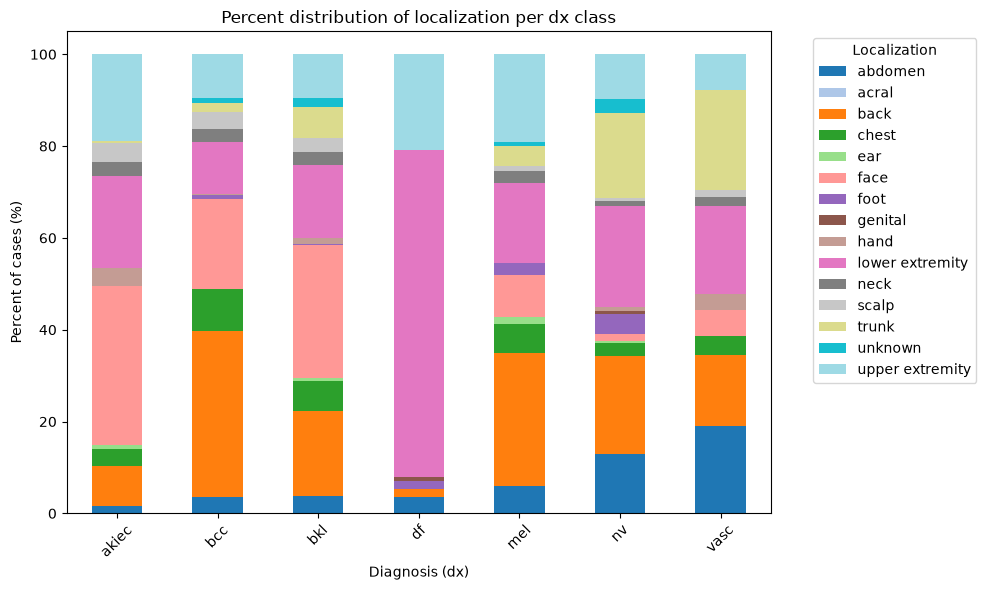

In [19]:
ax = diagnosis_loc_prop.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')

plt.title('Percent distribution of localization per dx class')
plt.xlabel('Diagnosis (dx)')
plt.ylabel('Percent of cases (%)')
plt.legend(title='Localization', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Wykres rozkładu lokalizacji zmiany z podziałem na klasy diagnostyczne wykazuje powiązanie między tą cechą a diagnozą. Aż 70% przypadków klasy `df` występuje na kończynach dolnych, a prawie 20% na górnych. Dodatkowo, zmiany nowotworowe `akiec` i `bcc` pojawiają się najczęściej w miejscach najbardziej narażonych na promieniowanie UV, co znajduje odzwierciedlenie w zbiorze danych (lokalizacje `face`, `back`, i `upper extremity`) stanowią około 60% swoich klas. Klasy takie jak `nv` (pieprzyki) czy `mel` (czerniak) są o wiele bardziej uniwersalne, choć i tak najczęściej znajdują się na plecach.

Cecha ta zostanie poddana testowi chi-kwadrat oraz Cramera by ocenić jej wartość predykcyjną

#### Test chi-kwadrat niezależności

$H_0$: Badane zmienne są niezależne.

$H_1$: Badane zmienne są zależne.

In [20]:
contingency_table = pd.crosstab(df["localization"], df["dx"])

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print(f"Chi-square: {chi2:.4f}")
print(f"p-value: {p_value:.4f}")

Chi-square: 2821.9102
p-value: 0.0000


Przed interpretacją wyniku ponownie zostają sprawdzone założenia testu chi-kwadrat.

In [21]:
# Tabela liczebności oczekiwanych
expected_table = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("Liczebności oczekiwane:")
display(expected_table.round(2))

# Kontrola założeń
print("Minimalna wartość expected:", expected.min())
print("Liczba komórek z expected < 5:", (expected < 5).sum())
print(
    "Procent komórek z expected < 5:",
    round((expected < 5).mean() * 100, 2), "%"
)

Liczebności oczekiwane:


dx,akiec,bcc,bkl,df,mel,nv,vasc
localization,,,,,,,
abdomen,33.37,52.45,112.15,11.74,113.58,684.22,14.49
acral,0.23,0.36,0.77,0.08,0.78,4.69,0.10
back,71.57,112.50,240.54,25.17,243.60,1467.53,31.08
chest,13.29,20.89,44.66,4.67,45.23,272.48,5.77
ear,1.83,2.87,6.15,0.64,6.22,37.49,0.79
face,24.33,38.24,81.75,8.55,82.79,498.77,10.56
foot,10.42,16.37,35.01,3.66,35.45,213.57,4.52
genital,1.57,2.46,5.27,0.55,5.33,32.14,0.68
hand,2.94,4.62,9.88,1.03,10.00,60.25,1.28


Minimalna wartość expected: 0.08037943085371942
Liczba komórek z expected < 5: 29
Procent komórek z expected < 5: 27.62 %


Założenia testu chi-kwadrat nie są spełnione, więc użyta zostaje alternatywna metoda (symulacja Monte Carlo)

In [22]:
contingency_table = pd.crosstab(
    df["localization"],
    df["dx"]
)

result = chi2_contingency(
    contingency_table,
    correction=False,
    method=MonteCarloMethod(n_resamples=100_000)
)

print("Chi-square:", result.statistic)
print("p-value Monte Carlo:", result.pvalue)

Chi-square: 2821.9101978213816
p-value Monte Carlo: 9.99990000099999e-06


In [23]:
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

print(f"Cramer's V: {cramers_v:.4f}")

Cramer's V: 0.2167


Choć test niezależności dowodzi, że zmienne mogą być zależne, współczynnik Cramera określa tę zależność jako słabą/umiarkowaną.

## ***3. Analiza identyfikatorów zmian oraz występowania powtórzeń***

In [24]:
duplicates = df[df.duplicated(subset="lesion_id", keep="first")]

duplicates_per_class = (
    duplicates.groupby("dx")
    .size()
    .reset_index(name="number_of_duplicates")
)

duplicates_per_class["duplicate_percentage"] = (
    duplicates_per_class["number_of_duplicates"]
    / df.groupby("dx").size().reindex(
        duplicates_per_class["dx"]
    ).values
    * 100
)

duplicates_per_class

,dx,number_of_duplicates,duplicate_percentage
0,akiec,99,30.275229
1,bcc,187,36.381323
2,bkl,372,33.848954
3,df,42,36.521739
4,mel,499,44.833783
5,nv,1302,19.418345
6,vasc,44,30.985915


In [25]:
lesion_stats = (
    df.groupby(['dx', 'lesion_id'])
      .size()
      .reset_index(name='image_count')
)

print(
    lesion_stats.groupby('dx')['image_count']
    .agg(
        number_of_lesions='count',
        mean_images_per_lesion='mean',
        max_images_per_lesion='max'
    )
)

       number_of_lesions  mean_images_per_lesion  max_images_per_lesion
dx                                                                     
akiec                228                1.434211                      4
bcc                  327                1.571865                      4
bkl                  727                1.511692                      6
df                    73                1.575342                      3
mel                  614                1.812704                      6
nv                  5403                1.240977                      6
vasc                  98                1.448980                      4


Przy pracy ze zbiorem HAM10000 istnieje ryzyko wystąpienia 'identity leakage' ze względu na występowanie wielu zdjęć niektórych zmian skórnych. Zdjęcia te dokumentują tę samą zmianę w innych warunkach, np. pod innym zbliżeniem lub kątem. Stanowią one około 30-35% dla większości z klas. Najbardziej narażona jest klasa `mel` (melanoma), gdzie zdjęcia zmiany skórnej, która już znajduje się w zbiorze, wynoszą prawie 45%, natomiast stosunkowo najmniej powtórek tej samej zmiany skórnej znajduje się w klasie `nv` (Melanocytic Nevi), gdzie stanowią one jedynie 20% całej klasy.

Jedna zmiana skórna w zbiorze może mieć nawet 6 reprezentacji, co podkreśla potrzebę podziału zbioru według kolumny `lesion_id`.

### 3.1. Wyświetlenie przykładowych zdjęć tej samej zmiany skórnej

Wyświetlam zdjęcia dla zmiany skórnej: HAM_0005132


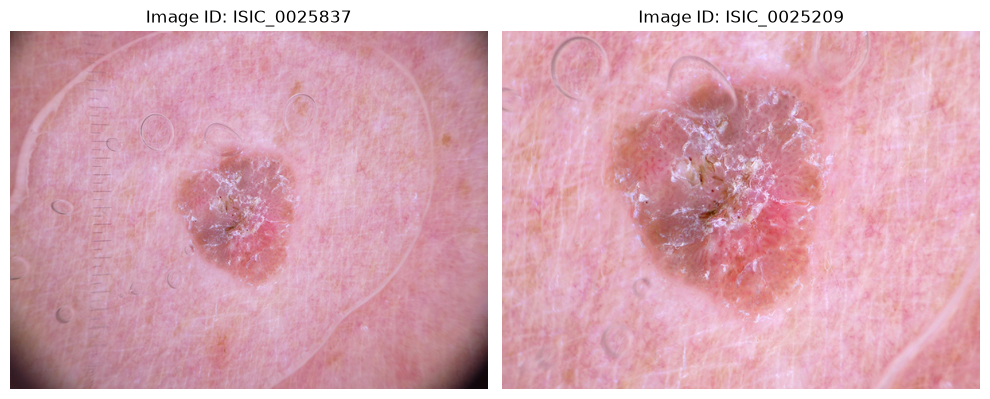

In [26]:
sample_lesion_id = duplicates['lesion_id'].iloc[4]
print(f"Wyświetlam zdjęcia dla zmiany skórnej: {sample_lesion_id}")

sample_images = df[df['lesion_id'] == sample_lesion_id]['image_id'].tolist()

num_images = len(sample_images)
fig, axes = plt.subplots(1, num_images, figsize=(5 * num_images, 5))

for ax, img_id in zip(axes, sample_images):
    img_path = os.path.join(image_dir, img_id + '.jpg')
    img = Image.open(img_path)
    
    ax.imshow(img)
    ax.set_title(f"Image ID: {img_id}")
    ax.axis('off')

plt.tight_layout()
plt.show()

## ***4. Analiza rozkładu klas***

In [27]:
print(df["dx"].value_counts(normalize=True) * 100)

dx
nv       66.949576
mel      11.113330
bkl      10.973540
bcc       5.132302
akiec     3.265102
vasc      1.417873
df        1.148278
Name: proportion, dtype: float64


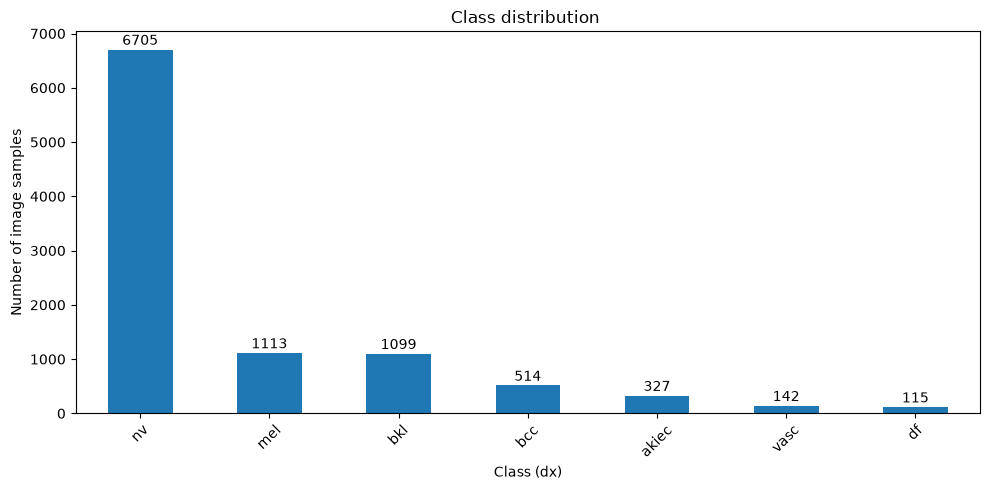

In [28]:
class_distribution(df)

W zbiorze danych występuje ogromny dysbalans między klasami - najliczniejsza klasa: `nv` (pieprzyki) stanowi prawie 67% zbioru, podczas gdy dwie najmniej liczne klasy nie stanowią nawet 2%. Wymaga to specjalnego podejścia, by prawidłowo wykonać ewaluacje modelu oraz by model nie faworyzował największej klasy.  

Ze względu na występowanie w zbiorze powtórek zdjęć tej samej zmiany skórnej, należy także zbadać ile zmian skórnych przypada na klasę.

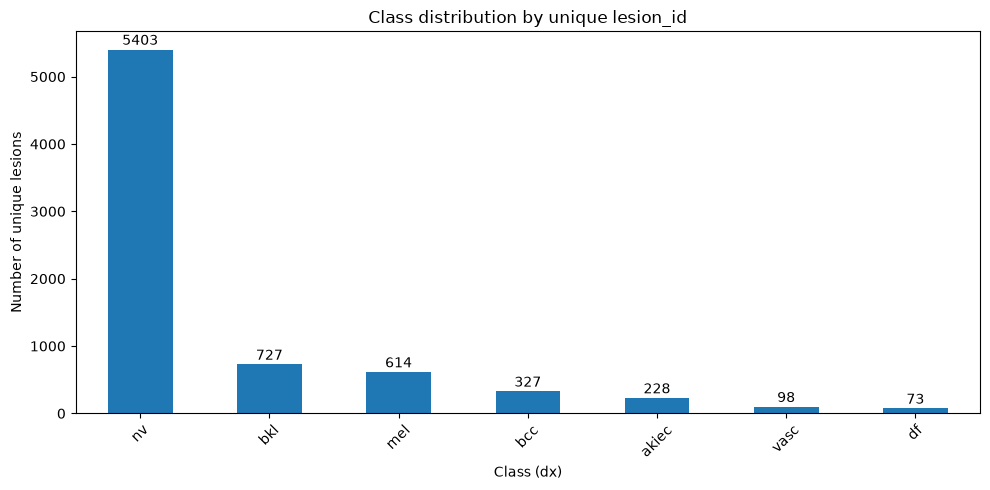

In [29]:
counts_class = (
    df.groupby('dx')['lesion_id']
    .nunique()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
bars = counts_class.plot(kind='bar')

plt.bar_label(bars.containers[0], fmt='%d', padding=1)

plt.title('Class distribution by unique lesion_id')
plt.xlabel('Class (dx)')
plt.ylabel('Number of unique lesions')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## ***5. Wnioski z etapu eksploracji i analizy danych***

Przeprowadzona eksploracyjna analiza danych pozwoliła zidentyfikować najważniejsze właściwości zbioru HAM10000. Ujawniła potencjalne problemy dotyczące jakości danych, które należy uwzględnić na dalszych etapach pracy ze zbiorem i przy przygotowaniach modeli klasyfikacyjnych:

- Dysbalans klas  

HAM10000 charakteryzuje się znaczną nierównowagą liczebności klas. Największa klasa (`nv` - tzw. pieprzyki) stanowią prawie 67% wszystkich obrazów. Najmniej liczne klasy (`df` i `vasc`) stanowią zaś mniej niż 1.5% zbioru. Taka dysproporcja może wprowadzić stonniczość do modelu wobec klas większościowych i uzyskiwania słabych wyników dla pomniejszych klas. 

Taki stan rzeczy wymaga użycia innych metryk oceny modelu poza *accuracy*. Należy skorzystać także z innych metryk, np. F1-score, oraz macierzy pomyłek, a także przeanalizować sposoby radzenia sobie z niezbalansowanymi danymi, tj. oversampling czy nadawanie klasom wag.

- Powtarzające się obrazy tych samych zmian skórnych  


Analiza `lesion_id` wykazała, że w zbiorze występuje wiele reprezentacji części zmian skórnych. Udział 'powtórek' różni się w zależności od klasy, jednak najbardziej odczuwalny jest on w klasie `mel`, gdzie zajmuje on 45% klasy. Wyklucza to losowy podział zbioru na dane treningowe i testowe, ze względu na duże prawdopodobieństwo wycieku danych, co zaburzyłoby wyniki ewaluacji modelu. Podział danych musi się odbyć względem `lesion_id` tak, by wszystkie obrazy tej samej zmiany skórnej znalazły się w tym samym zbiorze.

- Brak danych lub wartości niejednoznaczne  


W kolumnie `age` znaleziono 57 brakujących wartości, a w kolumnach `localization` i `sex` występują wartości oznaczone jako `unknown`.  Wymagają one specjalnego obsłużenia - należy zdecydować czy podjąć się imputacji danych czy potraktować je jako osobne kategorie. Zaobserwowano także 39 rekordów z wiekiem równym 0, jednak dostępne informacje nie pozwalają jednoznaczne stwierdzić, czy są to rzeczywiste dane, czy wartości zastępcze (równoważne NaN), więc zdecydowano o zachowaniu ich na etapie EDA w niezmienionej formie. 

- Zależność między lokalizacją zmiany skórnej a diagnozą  

Analiza wieku wykazała różnice w rozkładach tej cechy między klasami. Przykładowo, mediana klasy jest wyższa dla klasy `bcc` niż dla `nv`. Rozkłady poszczególnych klas jednak częściowo się pokrywają. Test chi-kwadrat wykazał statystyczną zależność między płcią a diagnozą, jednak test V-Cramera ocenia tę zależność jako słabą. Wiek pacjenta może więc zawierać informacje pomocne w klasyfikacji, jednak trudno na tym etapie ocenić ich rzeczywistą wartość predykcyjną. 

- Zależność między wiekiem a diagnozą  

Analiza lokalizacji zmian skórnych wykazała zróżnicowanie rozkładu lokalizacji między klasami. Przykładowo Dermatofibroma (klasa `df`) pojawia sie przede wszystkim na dolnych (lub rzadziej - górnych) kończynach, czego zbiór jest doskonałym odzwierciedleniem [1]. Testy wykazały statystycznie istotną zależność, a współczynnik V-Cramera (0.217) określa tę zależność jako słabą/umiarkowaną. Lokalizacja zmiany może więc być użyteczną cechą predykcyjną w dalszej analizie.

[1] https://twojeznamiona.pl/blog/dermatofibroma-czy-to-rak/

Potencjalne rzeczy do zbadania:
- Czy wszystkie 'powtórki' mają tę samą diagnozę?
- testy statystyczne na bazie liczby zmian skornych w klasie a nie obrazow